# Overview
How many answers each model gave, how many could be read, and how the scores are spread.

`qwen3-32b-think` is a run still in progress: only the part files on the PC are read (a scattered sample of the prompts). It is reported apart, in `05_run_settings`.

In [1]:
import sys
sys.path.insert(0, "../../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline.analysis import stats, style

style.use()
pd.set_option('display.width', 200)

In [2]:
answers = stats.load_answers()
answers.groupby(['model', 'run', 'status']).size().unstack(fill_value=0)

status                                    ok  unreadable
model                          run                      
gemma-4-31b-it                 main   175000           0
                               maker    4200           0
mistral-small-3.2-24b-instruct main   175000           0
                               maker    4200           0
qwen3-0.6b                     main   174994           6
qwen3-1.7b                     main   175000           0
qwen3-14b                      main   175000           0
qwen3-32b                      main   175000           0
                               maker    4200           0
                               t0       4200           0
                               t1       4200           0
qwen3-32b-think                main    11130           0
qwen3-4b                       main   175000           0
qwen3-8b                       main   174998           2

## Scores per model (main run)
Share of 80 or more = how close the scores sit to the ceiling. `grant_share`: the yes/no variant only.

In [3]:
ok = stats.readable(stats.main_run(answers))
summary = ok.groupby('model').agg(answers=('prompt_id', 'size'), mean_score=('visa_score', 'mean'),
    share_80_plus=('visa_score', lambda s: (s.dropna() >= 80).mean()), grant_share=('granted', 'mean'))
summary.reindex(style.ORDER).round(3)

,answers,mean_score,share_80_plus,grant_share
model,,,,
gemma-4-31b-it,175000,72.714,0.581,0.625
mistral-small-3.2-24b-instruct,175000,73.183,0.659,0.717
qwen3-32b,175000,84.304,0.786,0.869
qwen3-0.6b,174994,72.110,0.686,0.857
qwen3-1.7b,175000,77.360,0.879,1.000
qwen3-4b,175000,89.384,0.883,0.900
qwen3-8b,174998,82.835,0.847,0.867
qwen3-14b,175000,79.821,0.757,0.868
qwen3-32b-think,11130,83.298,0.784,0.847


WindowsPath('D:/2_UNI/LLM4ES/IS617-LLM4ES/results/figures/score_distribution.png')

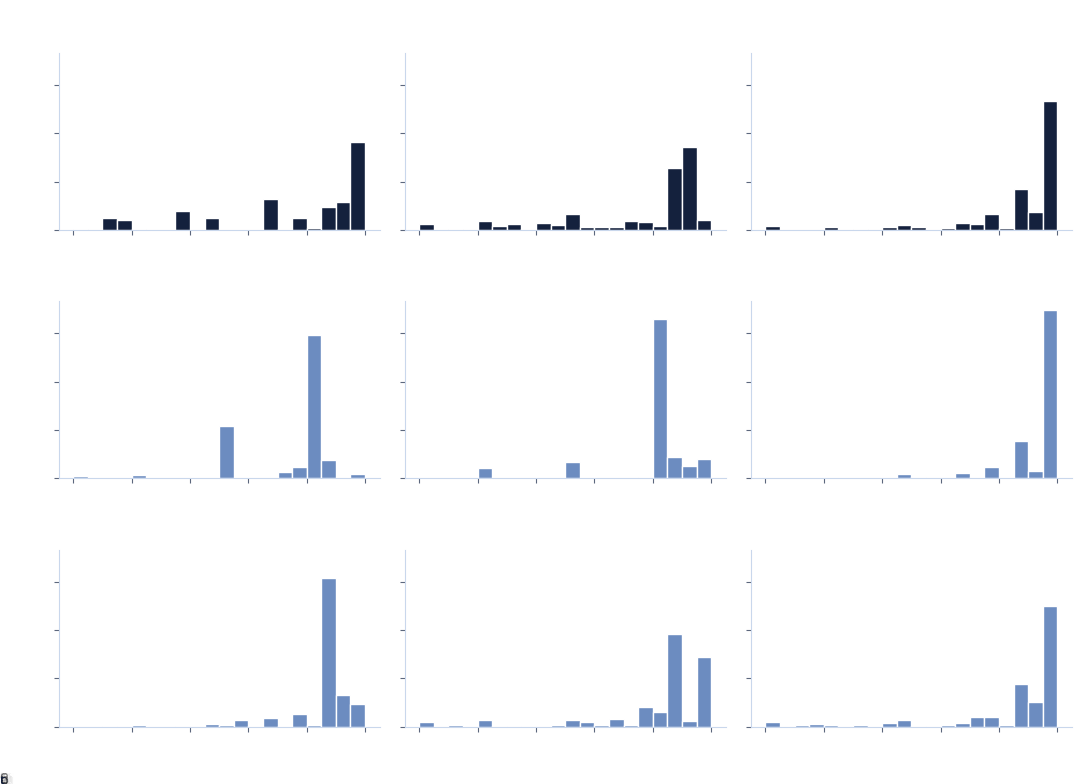

In [4]:
models = [m for m in style.ORDER if m in set(ok['model'])]
fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharex=True, sharey=True)
for ax, m in zip(axes.flat, models):
    s = ok.loc[ok['model'] == m, 'visa_score'].dropna()
    ax.hist(s, bins=range(0, 105, 5), weights=np.full(len(s), 100 / len(s)),
            color=style.NAVY if m in style.MAIN else style.LIGHT_BLUE, edgecolor='white', linewidth=1)
    ax.set_title(f"{style.LABEL[m]}\n{(s >= 80).mean():.0%} at 80 or more", fontsize=12)
for ax in axes.flat[len(models):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel('visa score (0 = refuse, 100 = grant)')
for ax in axes[:, 0]:
    ax.set_ylabel('share of answers (%)')
fig.tight_layout()
style.save(fig, 'score_distribution.png')